In [6]:
# ============================================================
# 基于 ConvNeXt-Tiny 的植物图像分类
# 实验内容：模型训练、验证评估、全量训练、测试集预测
# ============================================================

# ==================== 1. 导入相关库 ====================

import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torchvision import transforms, models, datasets
from torch.utils.data import Dataset, DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==================== 2. 参数设置 ====================

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 12

DATA_ROOT = (
    "/kaggle/input/competitions/2026task1/"
    "dataset-for-task2/dataset-for-task2"
)

TRAIN_DIR = os.path.join(DATA_ROOT, "train")
TEST_DIR = os.path.join(DATA_ROOT, "test")

TEMPLATE_PATH = (
    "/kaggle/input/competitions/2026task1/"
    "submission-for-task2.csv"
)

OUTPUT_DIR = "/kaggle/working"

VALIDATION_MODEL_PATH = os.path.join(
    OUTPUT_DIR, "convnext_validation_best.pth"
)

FINAL_MODEL_PATH = os.path.join(
    OUTPUT_DIR, "convnext_plant.pth"
)

SUBMISSION_PATH = os.path.join(
    OUTPUT_DIR, "submission.csv"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("运行设备：", DEVICE)

# 检查数据路径
assert os.path.isdir(TRAIN_DIR), "训练集目录不存在"
assert os.path.isdir(TEST_DIR), "测试集目录不存在"
assert os.path.isfile(TEMPLATE_PATH), "提交模板不存在"

print("数据路径检查通过")

# ==================== 3. 图像预处理 ====================

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = val_transform

# ==================== 4. 加载数据集 ====================

# 两份数据集使用相同的图片顺序和类别映射，
# 但训练集与验证集使用不同的图像变换。

train_dataset_full = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset_full = datasets.ImageFolder(
    TRAIN_DIR,
    transform=val_transform
)

classes = train_dataset_full.classes
num_classes = len(classes)

assert train_dataset_full.samples == val_dataset_full.samples, (
    "训练集和验证集的图片顺序不一致"
)

print("植物类别：", classes)
print("类别数量：", num_classes)
print("训练图片总数：", len(train_dataset_full))

# 检查类别
expected_classes = [
    "Black-grass",
    "Common wheat",
    "Loose Silky-bent",
    "Scentless Mayweed",
    "Sugar beet"
]

assert classes == expected_classes, (
    f"类别顺序异常：{classes}"
)

# ==================== 5. 划分训练集和验证集 ====================

all_indices = np.arange(len(train_dataset_full))
all_labels = np.array(train_dataset_full.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=SEED,
    stratify=all_labels
)

train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    val_dataset_full,
    val_indices
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("训练集数量：", len(train_dataset))
print("验证集数量：", len(val_dataset))
print("训练批次数量：", len(train_loader))
print("验证批次数量：", len(val_loader))

运行设备： cuda
数据路径检查通过
植物类别： ['Black-grass', 'Common wheat', 'Loose Silky-bent', 'Scentless Mayweed', 'Sugar beet']
类别数量： 5
训练图片总数： 500
训练集数量： 400
验证集数量： 100
训练批次数量： 25
验证批次数量： 7



开始验证实验
Epoch [01/12] Train Loss: 1.3777 | Train Acc: 0.4725 | Val Loss: 1.0611 | Val Acc: 0.7800
Epoch [02/12] Train Loss: 0.9704 | Train Acc: 0.7600 | Val Loss: 0.8200 | Val Acc: 0.8500
Epoch [03/12] Train Loss: 0.8201 | Train Acc: 0.8525 | Val Loss: 0.7538 | Val Acc: 0.9200
Epoch [04/12] Train Loss: 0.7835 | Train Acc: 0.8675 | Val Loss: 0.7397 | Val Acc: 0.8900
Epoch [05/12] Train Loss: 0.7181 | Train Acc: 0.9175 | Val Loss: 0.7188 | Val Acc: 0.9200
Epoch [06/12] Train Loss: 0.7155 | Train Acc: 0.9150 | Val Loss: 0.7114 | Val Acc: 0.9200
Epoch [07/12] Train Loss: 0.6959 | Train Acc: 0.9225 | Val Loss: 0.7146 | Val Acc: 0.9200
Epoch [08/12] Train Loss: 0.6909 | Train Acc: 0.9325 | Val Loss: 0.7143 | Val Acc: 0.9100
Epoch [09/12] Train Loss: 0.6838 | Train Acc: 0.9375 | Val Loss: 0.6987 | Val Acc: 0.9300
Epoch [10/12] Train Loss: 0.6612 | Train Acc: 0.9600 | Val Loss: 0.7022 | Val Acc: 0.9200
Epoch [11/12] Train Loss: 0.6571 | Train Acc: 0.9575 | Val Loss: 0.6996 | Val Acc: 0.9200
Ep

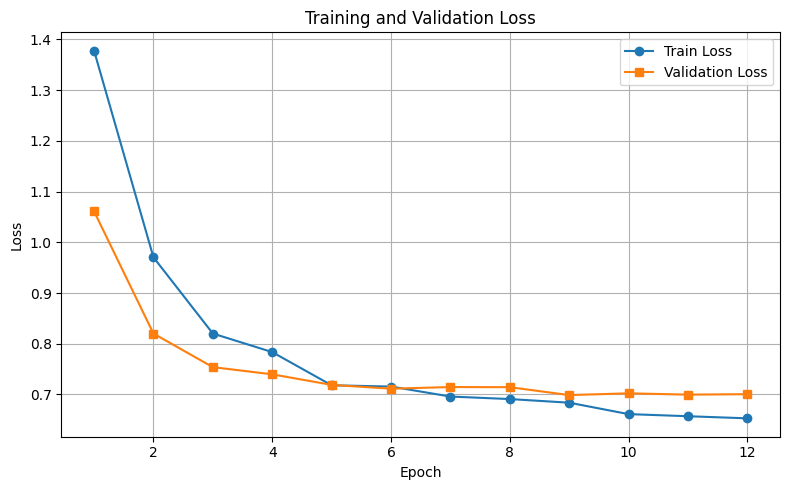

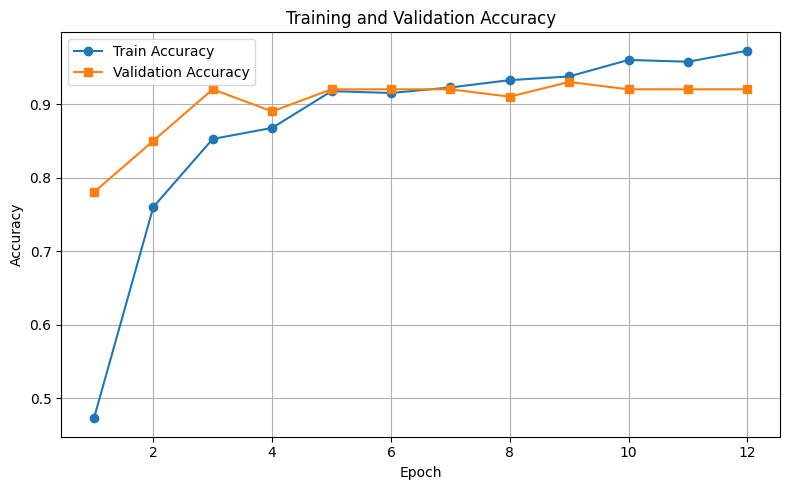


最佳验证模型评估结果
Validation Accuracy: 0.9300

分类报告：
                   precision    recall  f1-score   support

      Black-grass     0.7826    0.9000    0.8372        20
     Common wheat     1.0000    1.0000    1.0000        20
 Loose Silky-bent     0.8824    0.7500    0.8108        20
Scentless Mayweed     1.0000    1.0000    1.0000        20
       Sugar beet     1.0000    1.0000    1.0000        20

         accuracy                         0.9300       100
        macro avg     0.9330    0.9300    0.9296       100
     weighted avg     0.9330    0.9300    0.9296       100



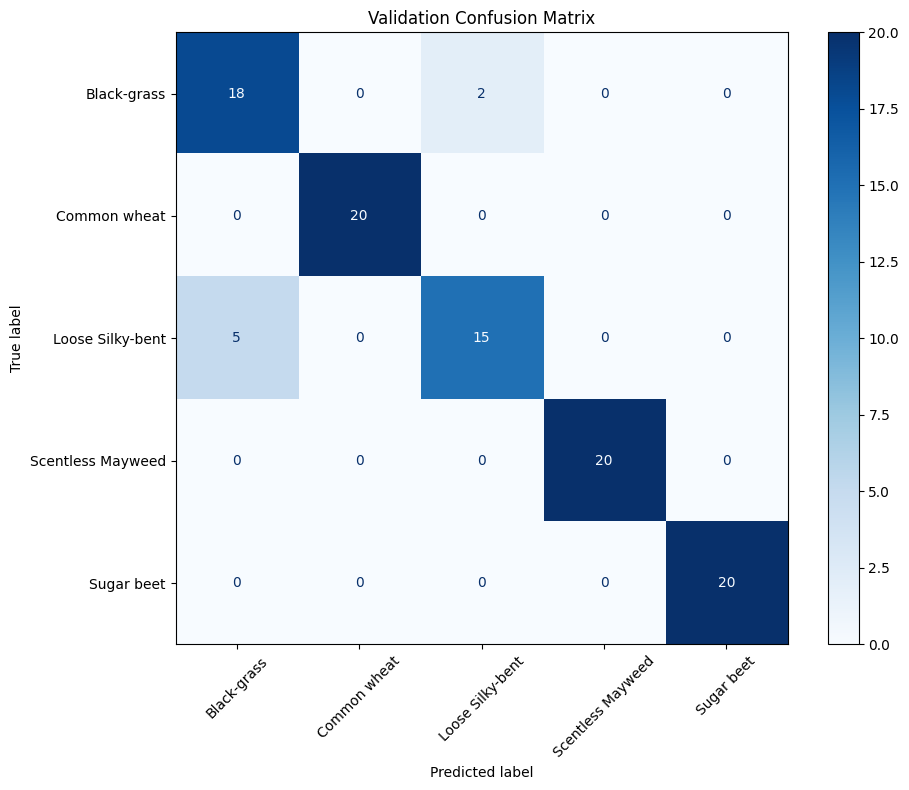


验证实验结果已保存至： /kaggle/working


In [7]:
# ==================== 6. 定义模型构建函数 ====================

def build_model():
    model = models.convnext_tiny(
        weights=models.ConvNeXt_Tiny_Weights.DEFAULT
    )

    in_features = model.classifier[2].in_features

    model.classifier[2] = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes)
    )

    return model.to(DEVICE)


def build_optimizer(model):
    optimizer = optim.AdamW(
        [
            {
                "params": model.features.parameters(),
                "lr": 2e-5
            },
            {
                "params": model.classifier.parameters(),
                "lr": 5e-4
            }
        ],
        weight_decay=0.01
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS,
        eta_min=1e-6
    )

    return optimizer, scheduler


criterion = nn.CrossEntropyLoss(
    label_smoothing=0.15
)

# ==================== 7. 训练与验证 ====================

model = build_model()
optimizer, scheduler = build_optimizer(model)

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_accuracy = -1.0
best_model_state = None

print("\n开始验证实验")

for epoch in range(EPOCHS):

    # ---------- 训练阶段 ----------
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        train_total += batch_size

    epoch_train_loss = train_loss_sum / train_total
    epoch_train_accuracy = train_correct / train_total

    # ---------- 验证阶段 ----------
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = images.size(0)

            val_loss_sum += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    epoch_val_loss = val_loss_sum / val_total
    epoch_val_accuracy = val_correct / val_total

    scheduler.step()

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_accuracy:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_accuracy:.4f}"
    )

    # 保存验证准确率最高的模型
    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = epoch_val_accuracy

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            {
                "model_state_dict": best_model_state,
                "classes": classes,
                "class_to_idx": train_dataset_full.class_to_idx,
                "img_size": IMG_SIZE,
                "epoch": epoch + 1,
                "val_accuracy": best_val_accuracy
            },
            VALIDATION_MODEL_PATH
        )

print("\n验证实验完成")
print("最佳验证准确率：", round(best_val_accuracy, 4))
print("最佳验证模型：", VALIDATION_MODEL_PATH)

# 恢复最佳验证模型
model.load_state_dict(best_model_state)

# ==================== 8. 绘制 Loss 曲线 ====================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o",
    label="Train Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "loss_curve.png"),
    dpi=300
)
plt.show()

# ==================== 9. 绘制准确率曲线 ====================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "accuracy_curve.png"),
    dpi=300
)
plt.show()

# ==================== 10. 验证集分类评估 ====================

model.eval()

val_true = []
val_pred = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        val_true.extend(labels.numpy())
        val_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(
    val_true,
    val_pred
)

print("\n最佳验证模型评估结果")
print(f"Validation Accuracy: {val_accuracy:.4f}")

print("\n分类报告：")

print(
    classification_report(
        val_true,
        val_pred,
        labels=list(range(num_classes)),
        target_names=classes,
        digits=4,
        zero_division=0
    )
)

# 混淆矩阵
cm = confusion_matrix(
    val_true,
    val_pred,
    labels=list(range(num_classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300
)

plt.show()

print("\n验证实验结果已保存至：", OUTPUT_DIR)


开始全量训练最终模型
Epoch [01/12] Full Train Loss: 1.4070
Epoch [02/12] Full Train Loss: 0.9241
Epoch [03/12] Full Train Loss: 0.8025
Epoch [04/12] Full Train Loss: 0.7592
Epoch [05/12] Full Train Loss: 0.7354
Epoch [06/12] Full Train Loss: 0.7169
Epoch [07/12] Full Train Loss: 0.6986
Epoch [08/12] Full Train Loss: 0.6857
Epoch [09/12] Full Train Loss: 0.6651
Epoch [10/12] Full Train Loss: 0.6590
Epoch [11/12] Full Train Loss: 0.6620
Epoch [12/12] Full Train Loss: 0.6626

最终模型已保存： /kaggle/working/convnext_plant.pth


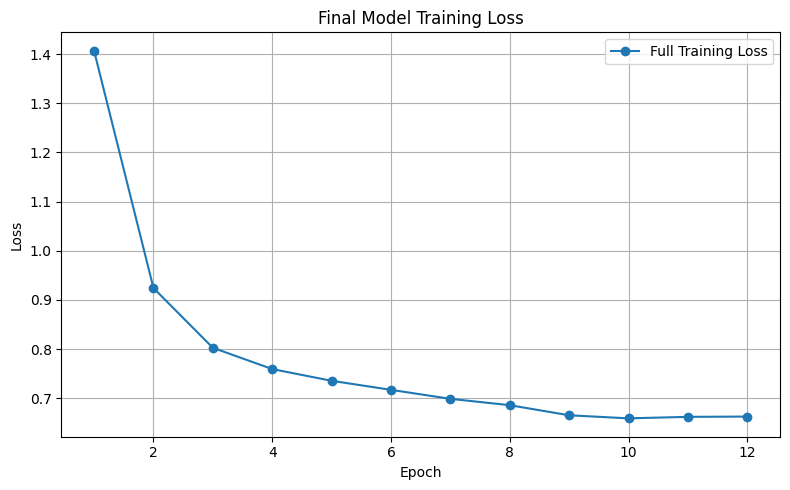

In [8]:
# ==================== 11. 使用全部训练图片训练最终模型 ====================

# 建立使用全部 500 张图片的训练数据加载器
full_train_loader = DataLoader(
    train_dataset_full,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("\n开始全量训练最终模型")

# 重新初始化模型
final_model = build_model()

final_optimizer, final_scheduler = build_optimizer(
    final_model
)

final_train_losses = []

for epoch in range(EPOCHS):

    final_model.train()

    running_loss = 0.0
    total = 0

    for images, labels in full_train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        final_optimizer.zero_grad()

        outputs = final_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        final_optimizer.step()

        running_loss += loss.item() * images.size(0)
        total += images.size(0)

    final_scheduler.step()

    epoch_loss = running_loss / total
    final_train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Full Train Loss: {epoch_loss:.4f}"
    )

# 保存最终模型
torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "classes": classes,
        "class_to_idx": train_dataset_full.class_to_idx,
        "img_size": IMG_SIZE,
        "epochs": EPOCHS
    },
    FINAL_MODEL_PATH
)

print("\n最终模型已保存：", FINAL_MODEL_PATH)

# 绘制最终模型训练 Loss 曲线
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    final_train_losses,
    marker="o",
    label="Full Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Final Model Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "final_training_loss.png"),
    dpi=300
)

plt.show()

In [9]:
# ==================== 12. 读取官方提交模板 ====================

submission = pd.read_csv(TEMPLATE_PATH)

assert "ID" in submission.columns, "模板缺少 ID 列"
assert "Category" in submission.columns, "模板缺少 Category 列"

# 按照官方模板的 ID 顺序寻找测试图片
test_files = [
    os.path.join(TEST_DIR, str(image_id))
    for image_id in submission["ID"]
]

missing_files = [
    path for path in test_files
    if not os.path.isfile(path)
]

assert not missing_files, (
    f"有 {len(missing_files)} 张测试图片不存在，"
    f"示例：{missing_files[:3]}"
)

print("测试图片数量：", len(test_files))


# ==================== 13. 构建测试数据集 ====================

class PlantTestDataset(Dataset):

    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        image_path = self.image_paths[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image


test_dataset = PlantTestDataset(
    test_files,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


# ==================== 14. TTA 融合预测 ====================

print("\n开始测试集预测")

final_model.eval()

predicted_labels = []

with torch.no_grad():

    for images in test_loader:

        images = images.to(DEVICE)

        # 原图预测
        outputs_original = final_model(images)

        # 水平翻转预测
        flipped_images = torch.flip(
            images,
            dims=[3]
        )

        outputs_flipped = final_model(
            flipped_images
        )

        # 融合两次输出
        outputs = (
            outputs_original + outputs_flipped
        ) / 2.0

        predictions = outputs.argmax(dim=1)

        predicted_labels.extend(
            predictions.cpu().numpy().tolist()
        )


# 将预测索引转换为类别名称
predicted_categories = [
    classes[index]
    for index in predicted_labels
]

assert len(predicted_categories) == len(submission), (
    "预测数量与提交模板行数不一致"
)


# ==================== 15. 生成提交文件 ====================

submission["Category"] = predicted_categories

submission = submission[["ID", "Category"]]

submission.to_csv(
    SUBMISSION_PATH,
    index=False
)

print("\n提交文件已生成：", SUBMISSION_PATH)

print("\n预测类别分布：")
print(submission["Category"].value_counts())

print("\n预测结果预览：")
print(submission.head(10))

print("\n提交文件形状：", submission.shape)

print("\n缺失值检查：")
print(submission.isnull().sum())

print("\n全部流程执行完成")

测试图片数量： 378

开始测试集预测

提交文件已生成： /kaggle/working/submission.csv

预测类别分布：
Category
Loose Silky-bent     114
Scentless Mayweed     90
Sugar beet            83
Black-grass           58
Common wheat          33
Name: count, dtype: int64

预测结果预览：
               ID           Category
0  xguwzbbzwk.png  Scentless Mayweed
1  oswkkowqvz.png   Loose Silky-bent
2  qcrkaeslvl.png   Loose Silky-bent
3  dtdslbefyx.png        Black-grass
4  yiileyjjhe.png        Black-grass
5  nlludoykla.png   Loose Silky-bent
6  cnheaqhxqt.png         Sugar beet
7  rzzjknapjs.png  Scentless Mayweed
8  grzdqhgeak.png   Loose Silky-bent
9  uvtvmblvjo.png         Sugar beet

提交文件形状： (378, 2)

缺失值检查：
ID          0
Category    0
dtype: int64

全部流程执行完成


In [10]:
import os
import pandas as pd
from sklearn.metrics import classification_report

OUTPUT_DIR = "/kaggle/working"

# 1. 保存分类报告
report = classification_report(
    val_true,
    val_pred,
    labels=list(range(num_classes)),
    target_names=classes,
    digits=4,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    os.path.join(OUTPUT_DIR, "validation_report.csv"),
    encoding="utf-8-sig"
)

# 2. 保存混淆矩阵
cm_df = pd.DataFrame(
    cm,
    index=classes,
    columns=classes
)

cm_df.to_csv(
    os.path.join(OUTPUT_DIR, "validation_confusion_matrix.csv"),
    encoding="utf-8-sig"
)

# 3. 保存每轮训练记录
history_df = pd.DataFrame({
    "Epoch": range(1, len(train_losses) + 1),
    "Train Loss": train_losses,
    "Validation Loss": val_losses,
    "Train Accuracy": train_accuracies,
    "Validation Accuracy": val_accuracies
})

history_df.to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("三个文件已生成！")
print("\n文件位置：")

print(os.path.join(OUTPUT_DIR, "validation_report.csv"))
print(os.path.join(OUTPUT_DIR, "validation_confusion_matrix.csv"))
print(os.path.join(OUTPUT_DIR, "training_history.csv"))

print("\n训练记录预览：")
print(history_df)

print("\n分类报告预览：")
print(report_df)

三个文件已生成！

文件位置：
/kaggle/working/validation_report.csv
/kaggle/working/validation_confusion_matrix.csv
/kaggle/working/training_history.csv

训练记录预览：
    Epoch  Train Loss  Validation Loss  Train Accuracy  Validation Accuracy
0       1    1.377729         1.061050          0.4725                 0.78
1       2    0.970378         0.820033          0.7600                 0.85
2       3    0.820105         0.753849          0.8525                 0.92
3       4    0.783512         0.739681          0.8675                 0.89
4       5    0.718054         0.718798          0.9175                 0.92
5       6    0.715544         0.711351          0.9150                 0.92
6       7    0.695865         0.714592          0.9225                 0.92
7       8    0.690889         0.714291          0.9325                 0.91
8       9    0.683754         0.698744          0.9375                 0.93
9      10    0.661223         0.702239          0.9600                 0.92
10     11    0.6

In [11]:
import os
import zipfile

output_dir = "/kaggle/working"
zip_path = "/kaggle/working/plant_experiment_results.zip"

# 需要打包的实验结果
files_to_save = [
    "convnext_validation_best.pth",
    "convnext_plant.pth",
    "submission.csv",
    "loss_curve.png",
    "accuracy_curve.png",
    "confusion_matrix.png",
    "final_training_loss.png",
    "validation_report.csv",
    "validation_confusion_matrix.csv",
    "training_history.csv"
]

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for filename in files_to_save:
        file_path = os.path.join(output_dir, filename)

        if os.path.isfile(file_path):
            zipf.write(file_path, arcname=filename)
            print("已打包：", filename)
        else:
            print("文件不存在，跳过：", filename)

print("\n压缩包已生成：", zip_path)

已打包： convnext_validation_best.pth
已打包： convnext_plant.pth
已打包： submission.csv
已打包： loss_curve.png
已打包： accuracy_curve.png
已打包： confusion_matrix.png
已打包： final_training_loss.png
已打包： validation_report.csv
已打包： validation_confusion_matrix.csv
已打包： training_history.csv

压缩包已生成： /kaggle/working/plant_experiment_results.zip
